In [5]:
import os, json
import numpy as np
import matplotlib.pyplot as plt

PROJECT = os.path.expanduser("~/spline_flows")
FIG = os.path.join(PROJECT, "figures")
FPS, H = 30, 32

e = np.load(os.path.join(PROJECT, "runs", "eval_test.npz"))
X, Y = e["X_test"], e["Y_test"]
models = {"Spline": e["spline"], "Waypoint": e["waypoint"]}
timing = json.load(open(os.path.join(PROJECT, "runs", "eval_timing.json")))
W, N = models["Spline"].shape[:2]
print(W, "windows,", N, "samples each")

COLOR = {"Spline": "#2a78d6", "Waypoint": "#eb6834", "Freeze": "#52514e", "Constant velocity": "#9a9893"}

3791 windows, 10 samples each


In [6]:
freeze = np.repeat(X[:, -1:], H, axis=1)
last_step = X[:, -1] - X[:, -2]
constvel = X[:, -1:] + last_step[:, None] * np.arange(1, H + 1)[None, :, None]
baselines = {"Freeze": freeze, "Constant velocity": constvel}


def vel(traj):
    return np.diff(traj, axis=-2) * FPS


def jerk(traj):
    return np.diff(traj, n=3, axis=-2) * FPS ** 3


def mse_per_window(pred, true):
    if pred.ndim == 4:
        true = true[:, None]
    return np.mean((pred - true) ** 2, axis=(-2, -1))


def rms(a):
    return float(np.sqrt(np.mean(a ** 2)))

In [7]:
rows = []
for name, M in models.items():
    pos = mse_per_window(M, Y)
    v = mse_per_window(vel(M), vel(Y))
    best = pos.argmin(axis=1)
    mean_pred = M.mean(axis=1)
    rows += [
        (f"{name}: one sample", np.sqrt(pos.mean()), np.sqrt(v.mean()), rms(jerk(M))),
        (f"{name}: mean of {N}", np.sqrt(mse_per_window(mean_pred, Y).mean()),
         np.sqrt(mse_per_window(vel(mean_pred), vel(Y)).mean()), rms(jerk(mean_pred))),
        (f"{name}: best of {N}", np.sqrt(pos.min(axis=1).mean()),
         np.sqrt(v[np.arange(W), best].mean()), rms(jerk(M[np.arange(W), best]))),
    ]
for name, B in baselines.items():
    rows.append((name, np.sqrt(mse_per_window(B, Y).mean()),
                 np.sqrt(mse_per_window(vel(B), vel(Y)).mean()), rms(jerk(B))))
rows.append(("Real motion", 0.0, 0.0, rms(jerk(Y))))

print(f"{'':24s}{'position (rad)':>16s}{'velocity (rad/s)':>18s}{'RMS jerk (rad/s^3)':>20s}")
for r in rows:
    print(f"{r[0]:24s}{r[1]:16.4f}{r[2]:18.3f}{r[3]:20.1f}")

print()
for name in models:
    t = timing[name.lower()]
    print(f"{name}: one window {t['ms_one_window']:.1f} ms, "
          f"batch of 256 {t['ms_per_window_in_batch_of_256']:.2f} ms per window")

print()
true_jump = np.sqrt(np.mean((Y[:, 0] - X[:, -1]) ** 2))
for name, M in models.items():
    jump = np.sqrt(np.mean((M[:, :, 0] - X[:, None, -1]) ** 2))
    spread = M.std(axis=1).mean()
    print(f"{name}: first-frame jump {jump:.4f} rad (real {true_jump:.4f}), spread across samples {spread:.4f} rad")

                          position (rad)  velocity (rad/s)  RMS jerk (rad/s^3)
Spline: one sample                0.2204             1.494               478.1
Spline: mean of 10                0.1785             1.209               207.3
Spline: best of 10                0.1831             1.327               472.0
Waypoint: one sample              0.2220             1.520              1076.9
Waypoint: mean of 10              0.1808             1.213               478.1
Waypoint: best of 10              0.1814             1.315              1045.8
Freeze                            0.2350             1.299                 0.0
Constant velocity                 0.8700             1.870                 0.0
Real motion                       0.0000             0.000               669.3

Spline: one window 267.3 ms, batch of 256 1.06 ms per window
Waypoint: one window 266.5 ms, batch of 256 1.17 ms per window

Spline: first-frame jump 0.1001 rad (real 0.0434), spread across samples 0.1130 rad


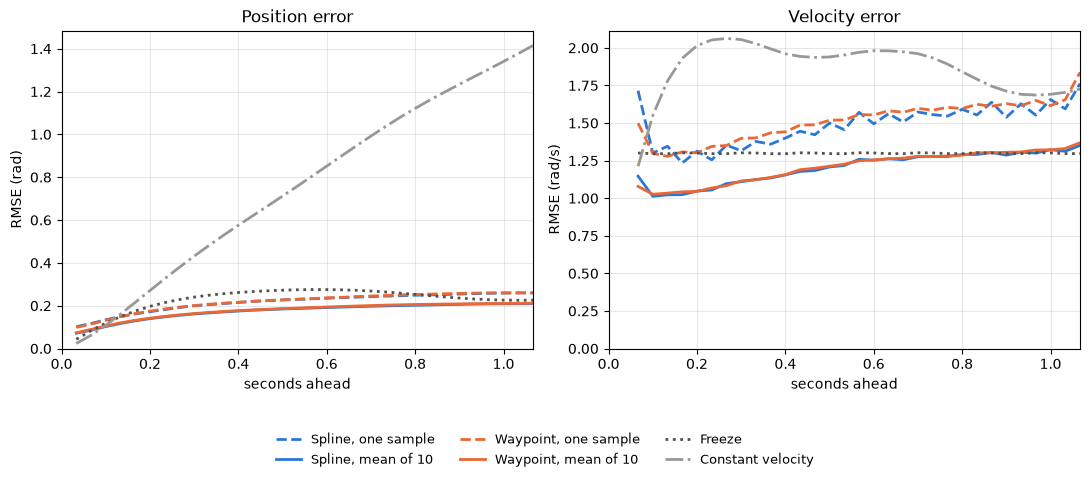

In [8]:
t_pos = np.arange(1, H + 1) / FPS
t_vel = np.arange(2, H + 1) / FPS

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for name, M in models.items():
    c = COLOR[name]
    axes[0].plot(t_pos, np.sqrt(np.mean((M - Y[:, None]) ** 2, axis=(0, 1, 3))), color=c, lw=2, ls="--",
                 label=f"{name}, one sample")
    axes[0].plot(t_pos, np.sqrt(np.mean((M.mean(1) - Y) ** 2, axis=(0, 2))), color=c, lw=2,
                 label=f"{name}, mean of {N}")
    axes[1].plot(t_vel, np.sqrt(np.mean((vel(M) - vel(Y)[:, None]) ** 2, axis=(0, 1, 3))), color=c, lw=2,
                 ls="--", label=f"{name}, one sample")
    axes[1].plot(t_vel, np.sqrt(np.mean((vel(M.mean(1)) - vel(Y)) ** 2, axis=(0, 2))), color=c, lw=2,
                 label=f"{name}, mean of {N}")
for name, B in baselines.items():
    ls = ":" if name == "Freeze" else "-."
    axes[0].plot(t_pos, np.sqrt(np.mean((B - Y) ** 2, axis=(0, 2))), color=COLOR[name], lw=2, ls=ls, label=name)
    axes[1].plot(t_vel, np.sqrt(np.mean((vel(B) - vel(Y)) ** 2, axis=(0, 2))), color=COLOR[name], lw=2, ls=ls,
                 label=name)
axes[0].set(title="Position error", xlabel="seconds ahead", ylabel="RMSE (rad)")
axes[1].set(title="Velocity error", xlabel="seconds ahead", ylabel="RMSE (rad/s)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_xlim(0, H / FPS)
    ax.set_ylim(bottom=0)
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=9, frameon=False)
fig.tight_layout(rect=(0, 0.14, 1, 1))
fig.savefig(os.path.join(FIG, "error_vs_horizon.png"), dpi=150)
plt.show()

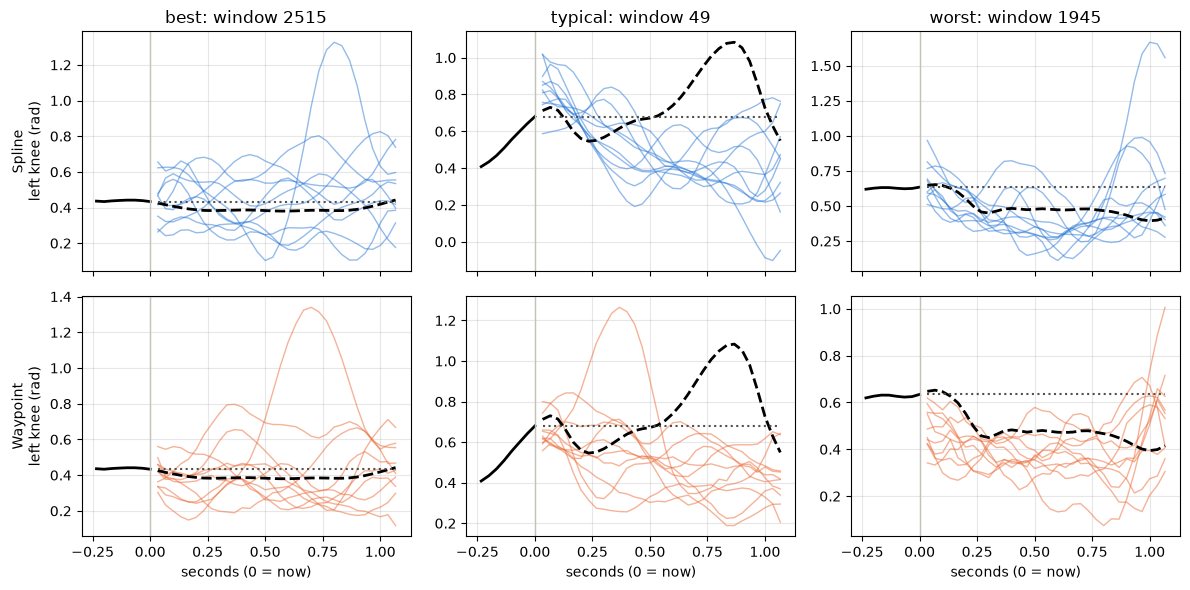

In [9]:
JOINT = 3
score = sum(mse_per_window(M.mean(1), Y) for M in models.values()) / len(models)
order = np.argsort(score)
picks = {"best": order[0], "typical": order[len(order) // 2], "worst": order[-1]}

t_hist = np.arange(-X.shape[1] + 1, 1) / FPS
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for col, (label, w) in enumerate(picks.items()):
    for row, (name, M) in enumerate(models.items()):
        ax = axes[row, col]
        for s in range(N):
            ax.plot(t_pos, M[w, s, :, JOINT], color=COLOR[name], lw=1, alpha=0.5)
        ax.plot(t_hist, X[w, :, JOINT], color="black", lw=2)
        ax.plot(t_pos, Y[w, :, JOINT], color="black", lw=2, ls="--")
        ax.plot(t_pos, freeze[w, :, JOINT], color=COLOR["Freeze"], lw=1.5, ls=":")
        ax.axvline(0, color="#c3c2b7", lw=1)
        ax.grid(alpha=0.3)
        if row == 0:
            ax.set_title(f"{label}: window {w}")
        if col == 0:
            ax.set_ylabel(f"{name}\nleft knee (rad)")
        if row == 1:
            ax.set_xlabel("seconds (0 = now)")
fig.tight_layout()
fig.savefig(os.path.join(FIG, "examples_left_knee.png"), dpi=150)
plt.show()

Spline: speed vs error correlation +0.52
Waypoint: speed vs error correlation +0.52


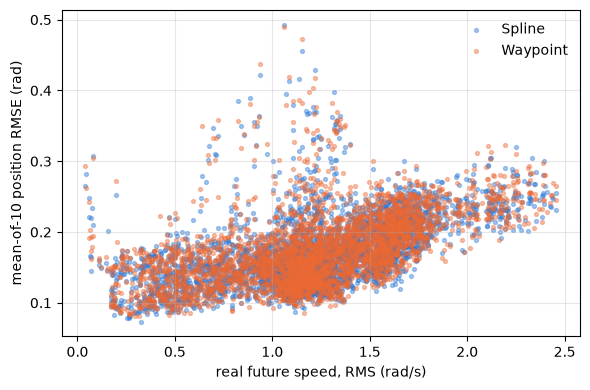

In [10]:
speed = np.sqrt(np.mean(vel(Y) ** 2, axis=(1, 2)))
fig, ax = plt.subplots(figsize=(6, 4))
for name, M in models.items():
    err = np.sqrt(mse_per_window(M.mean(1), Y))
    ax.scatter(speed, err, s=8, alpha=0.4, color=COLOR[name], label=name)
    print(f"{name}: speed vs error correlation {np.corrcoef(speed, err)[0, 1]:+.2f}")
ax.set(xlabel="real future speed, RMS (rad/s)", ylabel=f"mean-of-{N} position RMSE (rad)")
ax.grid(alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(FIG, "error_vs_speed_v2.png"), dpi=150)
plt.show()